# Land Use / Land Cover from Sentinel-1 radar only
**Deep-learning semantic segmentation with low-resolution (30 m) SAR data, and a prototype that produces 12 monthly maps.**

> **Problem statement.** Optical satellites cannot see through clouds; radar can, but SAR images are noisy and hard to interpret.
> Can a deep-learning model that uses *only* low-resolution Sentinel-1 data produce reliable monthly land-cover maps, and support
> measuring change over 12 months? How much do classification errors and seasonal radar effects distort the measured change?

This notebook is the report of the finished project. Data collection and training were run with the scripts in this folder
(`collect_data.py`, `train.py`, `analysis.py`, ...); here the **saved results are loaded and displayed**, so the notebook runs in a few minutes.
Only the prototype cell (section 5) needs internet access (Microsoft Planetary Computer, no account or key).

**Headline result:** 3 grouped classes (Vegetation & open land / Built-up / Water): **88.0 % overall accuracy on test cities never seen in training**
(mIoU 0.776). With the 6 original classes the same model reaches only about 70 %, because SAR cannot separate trees, grass, cropland and bare soil.

In [1]:
import glob, json, os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown

for cand in [os.getcwd(), os.path.expanduser("~/vault/LULC/LULC"), os.path.expanduser("~/LULC"),
             os.path.expanduser("~/LULC_proj"), os.path.dirname(os.getcwd())]:
    if os.path.exists(os.path.join(cand, "config.py")):
        os.chdir(cand); break
sys.path.insert(0, os.getcwd())
print("project folder:", os.getcwd())
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

def show_image(path, width=None):
    if os.path.exists(path):
        display(Image(filename=path, width=width))
    else:
        print(f"(not found: {path} - run the script that creates it, see README)")

def show_table(path, **kw):
    if os.path.exists(path):
        display(pd.read_csv(path, **kw))
    else:
        print(f"(not found: {path})")

MODEL = "models/lulc_unet.pt"
HIST = "models/lulc_unet_results.json"

project folder: /home/jovyan/vault/LULC/LULC


## 1. Dataset and preprocessing

| Item | Choice |
|---|---|
| **Input data** | Sentinel-1 RTC (VV and VH polarisation) from the Microsoft Planetary Computer (STAC API, free, no key) |
| **Labels** | ESA WorldCover 2021, merged into 6 base classes (Trees, Grass/Shrub, Cropland, Built-up, Bare/Snow, Water) |
| **Regions** | about 100 cities on all continents: 44 training/validation cities, about 50 additional training cities, 8 held-out **test cities** (Hamburg, Vienna, Hyderabad, Accra, Chengdu, Denver, Santiago, Brisbane) |
| **Period** | year 2021, 12 monthly median composites per tile |
| **Resolution** | **30 m** (low resolution as required): the 10 m data is area-averaged to 30 m |
| **Tiles** | 256 x 256 pixels at 30 m = 7.7 km x 7.7 km, stored as `.npz` |
| **Split** | **geographic**: whole cities are held out, so the test score measures generalisation to unseen cities |

**Preprocessing steps**
1. *Calibration and terrain correction:* done by the provider (the RTC product is radiometrically terrain-corrected).
2. *dB conversion:* backscatter is converted to decibels and clipped to a valid range (clean_s1 in `features.py`).
3. *Speckle reduction:* monthly median composite and 10 m -> 30 m area averaging; an optional Lee filter (`--speckle 5`) was tested as a variant.
4. *Normalisation:* fixed scaling of the dB values.
5. *Patching:* 256 x 256 tiles centred on the city or a random position up to 40 km away.
6. *Label matching:* WorldCover is resampled (mode) to the same 30 m grid as the radar tile.
7. *Augmentation:* random 90-degree rotations, flips, a random target month, and (final model) small Gaussian noise and brightness jitter.
8. *Quality filter:* tiles with filled/constant radar or a single class (sea only) are removed automatically.

Tiles per split:
 split
train    278
test      30
val       28

Cities per split:
 split
test      8
train    89
val       8

Class distribution (% of labelled pixels) of the original dataset, 6 base classes:


,Trees,Grass/Shrub,Cropland,Built-up,Bare/Snow,Water
train,25.56,13.60,13.03,33.03,4.23,10.55
val,18.76,22.05,15.11,36.67,1.36,6.06
test,23.52,19.05,15.92,31.84,5.40,4.27


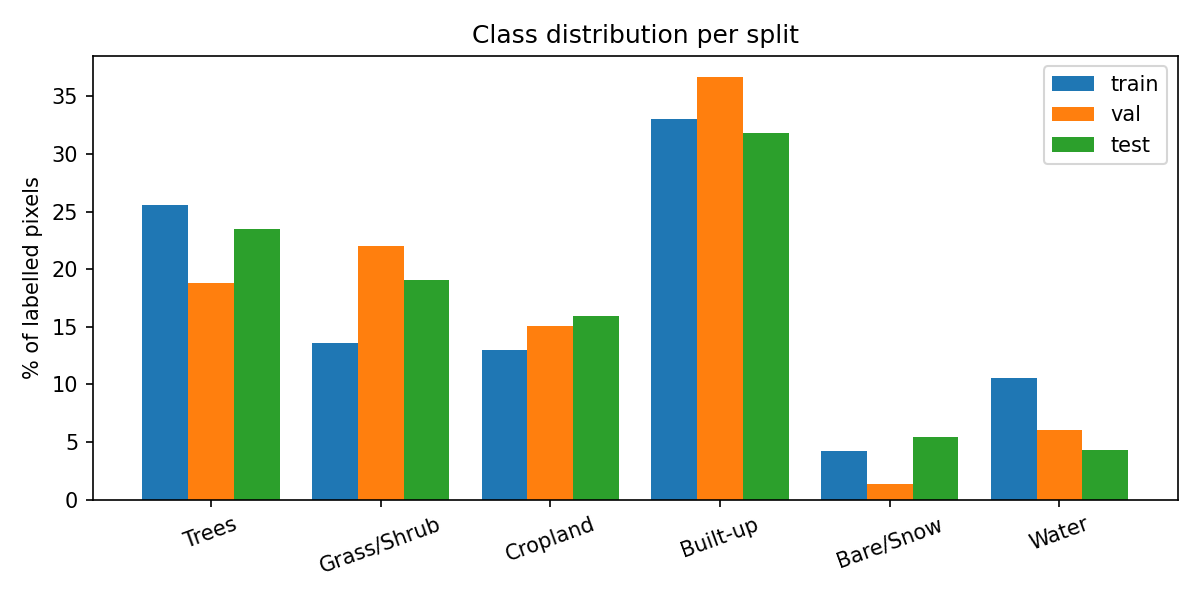

In [2]:
idx_path = "data/index.csv"
if os.path.exists(idx_path):
    idx = pd.read_csv(idx_path)
    print("Tiles per split:\n", idx.split.value_counts().to_string())
    print("\nCities per split:\n", idx.groupby("split").site.nunique().to_string())
else:
    print("data/ folder not available here; showing saved EDA results instead")
print("\nClass distribution (% of labelled pixels) of the original dataset, 6 base classes:")
show_table("outputs/eda/class_distribution.csv", index_col=0)
show_image("outputs/eda/class_distribution.png", width=600)

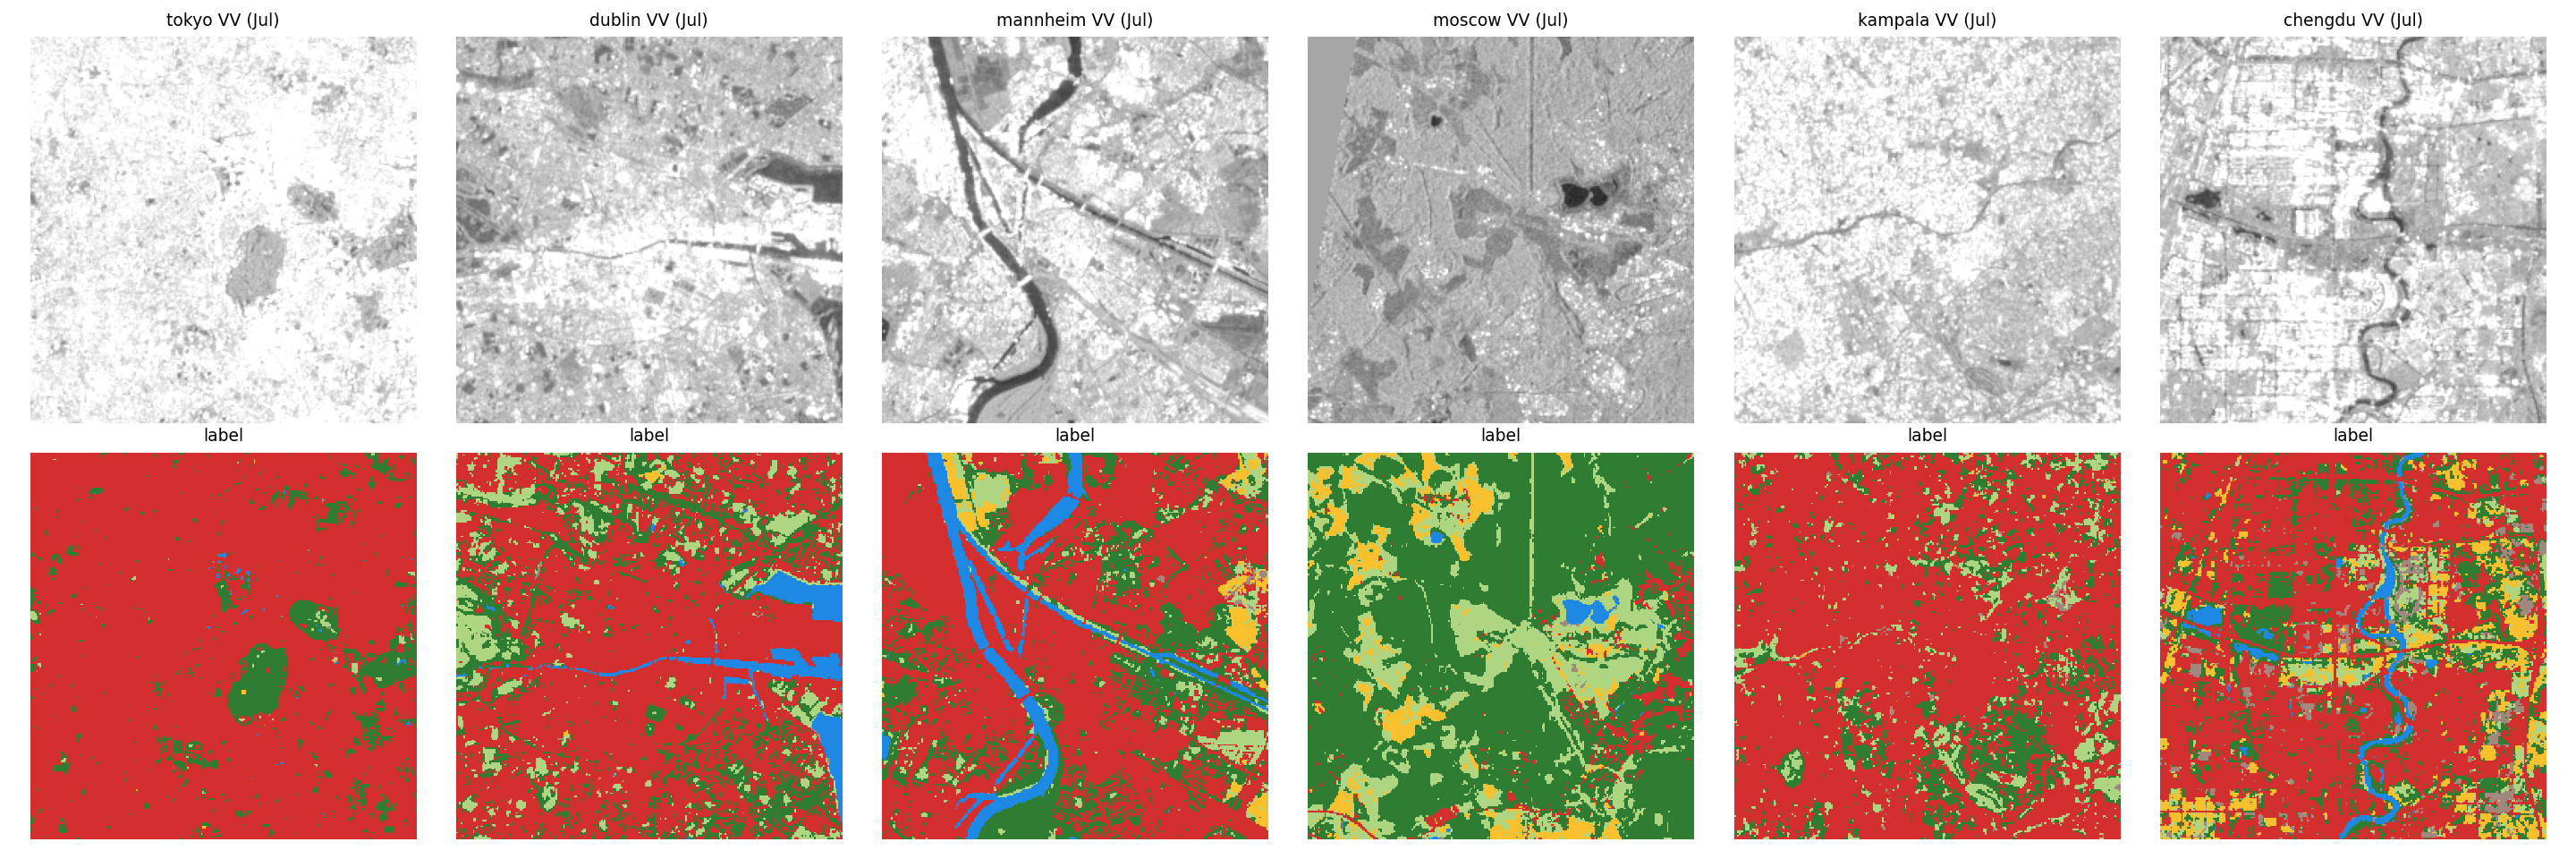

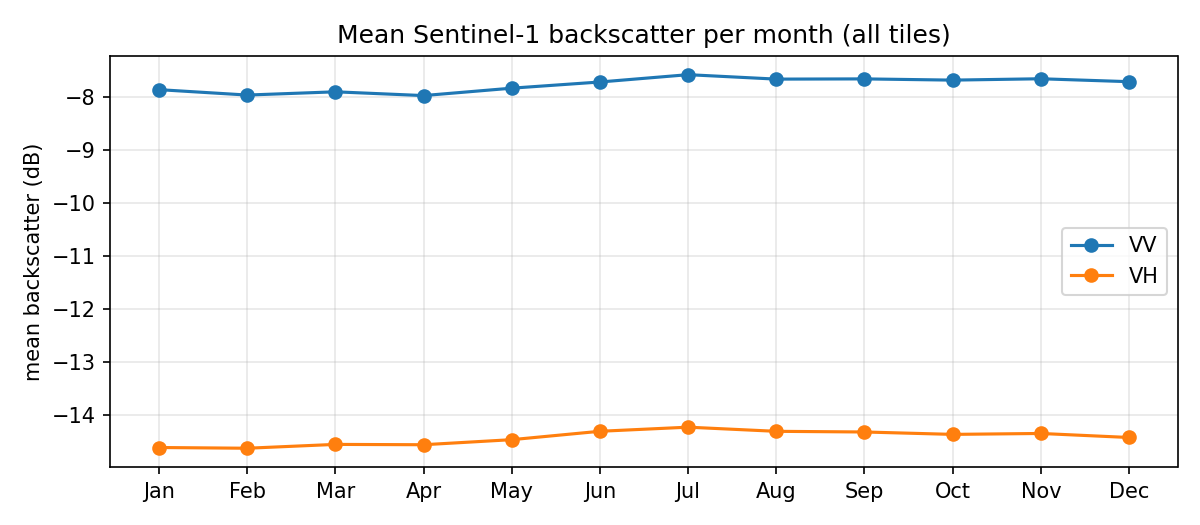

In [3]:
show_image("outputs/eda/eda_examples.png")
show_image("outputs/eda/backscatter_per_month.png", width=600)

## 2. Model and reasoning

* **Architecture: U-Net with a ResNet50 encoder** (ImageNet-pretrained, `segmentation_models_pytorch`). A U-Net outputs a label for every pixel, and its skip connections keep fine spatial detail at 30 m. Pretrained encoders converge faster and generalise better on a small dataset.
* **Input: 19 channels.** VV, VH and VV-VH of the target month, plus yearly statistics of VV and VH (mean, std, min, max) and four seasonal means. The yearly context helps to separate surfaces that look alike in a single month.
* **Loss:** class-weighted cross-entropy + Dice (rare classes such as water are not ignored). **Optimiser:** AdamW with a one-cycle learning-rate schedule, mixed precision.
* **Regularisation:** dropout (0.2) on the decoder output, noise augmentation, weight decay 1e-3.
* **Model selection:** the checkpoint with the best **validation** mIoU is kept; the test set is evaluated once at the end.
* **Class grouping:** SAR cannot reliably separate trees, grass, cropland and bare soil. The final model therefore predicts 3 classes, and the 6-class results are reported alongside (section 4).

In [4]:
try:
    import torch
    ck = torch.load(MODEL, map_location="cpu")
    print({k: ck[k] for k in ["arch", "encoder", "in_channels", "scheme", "features", "classes"]})
    from models import build_model
    m = build_model(ck["arch"], ck["encoder"], ck["in_channels"], len(ck["classes"]), pretrained=False)
    print(f"parameters: {sum(p.numel() for p in m.parameters())/1e6:.1f} M")
except Exception as e:
    print("model file not available here:", type(e).__name__, "- details are in the table above and in models/lulc_unet_results.json")
if os.path.exists(HIST):
    a = json.load(open(HIST))["args"]
    print("\nTraining arguments:", {k: a[k] for k in ["epochs", "bs", "lr", "weight_decay", "dropout", "aug", "samples_per_tile", "arch", "encoder", "features", "scheme"] if k in a})

{'arch': 'unet', 'encoder': 'resnet50', 'in_channels': 19, 'scheme': '3', 'features': 'rich', 'classes': ['Vegetation & open land', 'Built-up', 'Water']}
parameters: 32.6 M

Training arguments: {'epochs': 60, 'bs': 32, 'lr': 0.0003, 'weight_decay': 0.001, 'dropout': 0.2, 'aug': 0.05, 'samples_per_tile': 8, 'arch': 'unet', 'encoder': 'resnet50', 'features': 'rich', 'scheme': '3'}


## 3. Training performance

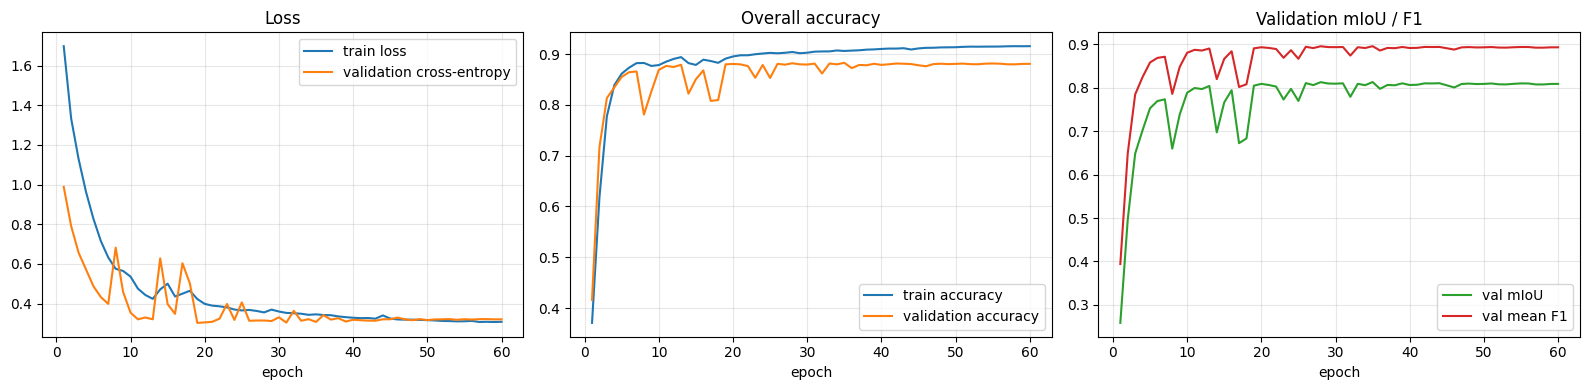

best epoch 35 | best validation mIoU 0.8133 | validation OA at best epoch 0.8827
final train accuracy 0.915 vs validation accuracy 0.881: small gap, no strong overfitting


In [5]:
if os.path.exists(HIST):
    h = json.load(open(HIST))
    H = pd.DataFrame(h["history"])
    fig, ax = plt.subplots(1, 3, figsize=(16, 4))
    ax[0].plot(H.epoch, H.train_loss, label="train loss"); ax[0].plot(H.epoch, H.val_loss, label="validation cross-entropy")
    ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].plot(H.epoch, H.train_acc, label="train accuracy"); ax[1].plot(H.epoch, H.val_acc, label="validation accuracy")
    ax[1].set_title("Overall accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend(); ax[1].grid(alpha=.3)
    ax[2].plot(H.epoch, H.val_mIoU, label="val mIoU", color="tab:green"); ax[2].plot(H.epoch, H.val_mF1, label="val mean F1", color="tab:red")
    ax[2].set_title("Validation mIoU / F1"); ax[2].set_xlabel("epoch"); ax[2].legend(); ax[2].grid(alpha=.3)
    plt.tight_layout(); plt.show()
    print(f"best epoch {h['best_epoch']} | best validation mIoU {h['best_val_mIoU']:.4f} | validation OA at best epoch {h['best_val_OA']:.4f}")
    print(f"final train accuracy {H.train_acc.iloc[-1]:.3f} vs validation accuracy {H.val_acc.iloc[-1]:.3f}: small gap, no strong overfitting")
else:
    print("history file not found - showing the saved figure instead")
    show_image("outputs/analysis/training_curves.png")

## 4. Results on the test cities (never seen in training)
Test set = 8 held-out cities, all 12 months, flip averaging (test-time augmentation).

Overall accuracy 0.8804 | mIoU 0.7764 | mean F1 0.8734



,IoU,F1,precision,recall,support_pixels
Vegetation & open land,0.827940,0.905872,0.933122,0.880168,15074064
Built-up,0.714284,0.833332,0.792137,0.879048,7511376
Water,0.787066,0.880847,0.867568,0.894539,1007520


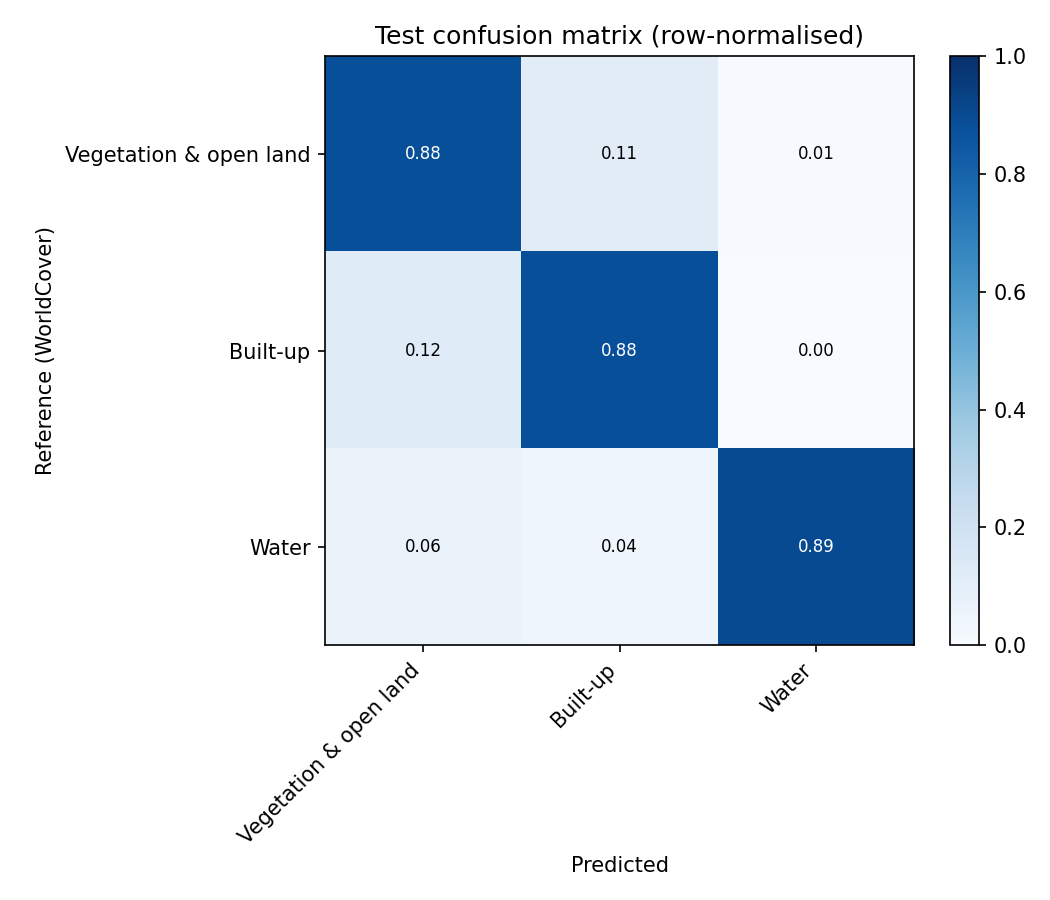

In [6]:
t = json.load(open("outputs/analysis/test_metrics.json"))
print(f"Overall accuracy {t['overall_acc']:.4f} | mIoU {t['mIoU']:.4f} | mean F1 {t['mF1']:.4f}\n")
show_table("outputs/analysis/per_class_metrics.csv", index_col=0)
show_image("outputs/analysis/confusion_matrix.png", width=520)

### Variant comparison
The most important finding: **class grouping matters far more than architecture or hyper-parameters.**

In [7]:
s = pd.read_csv("outputs/search.csv")
s = s.assign(classes=s.scheme.map({"6": 6, "5": 5, "4veg": 4, "4open": 4, "3": 3}))
cols = ["scheme", "classes", "arch", "encoder", "features", "val_OA", "val_mIoU", "test_OA", "test_mIoU"]
print("A) Class schemes (same U-Net ResNet50, rich features):")
display(s.sort_values("classes", ascending=False)[cols])

A) Class schemes (same U-Net ResNet50, rich features):


,scheme,classes,arch,encoder,features,val_OA,val_mIoU,test_OA,test_mIoU
4,6,6,unet,resnet50,rich,0.7073,0.5054,0.6982,0.5427
3,5,5,unet,resnet50,rich,0.7819,0.5636,0.7642,0.6051
2,4veg,4,unet,resnet50,rich,0.8492,0.6180,0.8253,0.6571
1,4open,4,unet,resnet50,rich,0.7997,0.6787,0.8077,0.6831
0,3,3,unet,resnet50,rich,0.8755,0.8013,0.8743,0.7641


In [8]:
arch = pd.DataFrame([
    ["U-Net", "ResNet50", 0.7153, 0.5089, 0.7037, 0.5377],
    ["U-Net", "ResNet34", 0.7056, 0.5012, 0.6941, 0.5335],
    ["U-Net++", "ResNet34", 0.7053, 0.4987, 0.7047, 0.5461],
    ["U-Net", "EfficientNet-B3", 0.6981, 0.4967, 0.6925, 0.4986],
    ["MAnet", "ResNet34", 0.6907, 0.4936, 0.6923, 0.5112],
    ["DeepLabV3+", "ResNet50", 0.6977, 0.4934, 0.6853, 0.5192],
    ["FPN", "ResNet34", 0.6845, 0.4735, 0.6893, 0.5256],
], columns=["architecture", "encoder", "val_OA", "val_mIoU", "test_OA", "test_mIoU"])
print("B) Architecture search (6 classes, base 7-channel features). All architectures land within about 2 points of each other:")
display(arch)

B) Architecture search (6 classes, base 7-channel features). All architectures land within about 2 points of each other:


,architecture,encoder,val_OA,val_mIoU,test_OA,test_mIoU
0,U-Net,ResNet50,0.7153,0.5089,0.7037,0.5377
1,U-Net,ResNet34,0.7056,0.5012,0.6941,0.5335
2,U-Net++,ResNet34,0.7053,0.4987,0.7047,0.5461
3,U-Net,EfficientNet-B3,0.6981,0.4967,0.6925,0.4986
4,MAnet,ResNet34,0.6907,0.4936,0.6923,0.5112
5,DeepLabV3+,ResNet50,0.6977,0.4934,0.6853,0.5192
6,FPN,ResNet34,0.6845,0.4735,0.6893,0.5256


In [9]:
rows = []
for f in sorted(glob.glob("models/tune/*_results.json") + glob.glob("models/tune2/*_results.json") + glob.glob("models/more_data/*_results.json")):
    j = json.load(open(f)); a = j["args"]
    rows.append([f.split("models/")[1].replace("_results.json", ""), a.get("features"), a.get("lr"), a.get("weight_decay"),
                 a.get("dropout", 0), a.get("aug", 0), a.get("samples_per_tile"),
                 round(j["best_val_OA"], 4), round(j["best_val_mIoU"], 4), round(j["test"]["overall_acc"], 4)])
if rows:
    print("C) Tuning of the 3-class model (features, learning rate, regularisation, augmentation, amount of data):")
    display(pd.DataFrame(rows, columns=["run", "features", "lr", "weight_decay", "dropout", "aug", "samples/tile", "val_OA", "val_mIoU", "test_OA"]))
    print("Tuning changed the result by less than one point. More training cities (135 -> 278 tiles, last row 'more_data') gave the only clear gain (+0.5 points OA, +1.7 points test mIoU).")
else:
    print("(tuning result files are not in this folder)")

C) Tuning of the 3-class model (features, learning rate, regularisation, augmentation, amount of data):


,run,features,lr,weight_decay,dropout,aug,samples/tile,val_OA,val_mIoU,test_OA
0,more_data/m1,rich,0.0003,0.0010,0.2,0.05,8,0.8827,0.8133,0.8792
1,tune/t1_reg,rich,0.0003,0.0010,0.2,0.05,4,0.8732,0.7976,0.8737
2,tune/t2_reg_s8,rich,0.0003,0.0010,0.2,0.05,8,0.8790,0.8070,0.8735
3,tune/t3_lr1e3,rich,0.0010,0.0001,0.0,0.00,4,0.8779,0.8035,0.8728
4,tune/t4_base,base,0.0003,0.0001,0.0,0.00,4,0.8738,0.7983,0.8714
5,tune2/a_strongreg,rich,0.0003,0.0010,0.3,0.10,4,0.8692,0.7926,0.8684
6,tune2/b_lr6e4_wd1e2,rich,0.0006,0.0100,0.2,0.05,4,0.8761,0.8022,0.8708
7,tune2/c_seed1,rich,0.0003,0.0010,0.2,0.05,4,0.8747,0.7994,0.8702


Tuning changed the result by less than one point. More training cities (135 -> 278 tiles, last row 'more_data') gave the only clear gain (+0.5 points OA, +1.7 points test mIoU).


Accuracy per test city and per month:


,site,tiles,OA,mIoU,mF1,dominant_class,%Vegetation & open land,%Built-up,%Water
0,denver,4,0.733570,0.534990,0.692649,Built-up,44.2,55.2,0.6
1,chengdu,4,0.846611,0.688298,0.812880,Vegetation & open land,70.5,26.3,3.2
2,accra,3,0.864199,0.789789,0.881065,Vegetation & open land,46.5,42.9,10.6
3,hyderabad,4,0.890374,0.808405,0.893321,Vegetation & open land,58.5,33.5,8.1
4,hamburg,4,0.906111,0.764956,0.863232,Vegetation & open land,74.7,19.0,6.3
5,vienna,4,0.925469,0.810889,0.894208,Vegetation & open land,71.5,25.4,3.1
6,brisbane,3,0.929212,0.816377,0.897423,Vegetation & open land,72.5,24.0,3.4
7,santiago,4,0.955994,0.634859,0.689935,Vegetation & open land,70.6,29.3,0.1


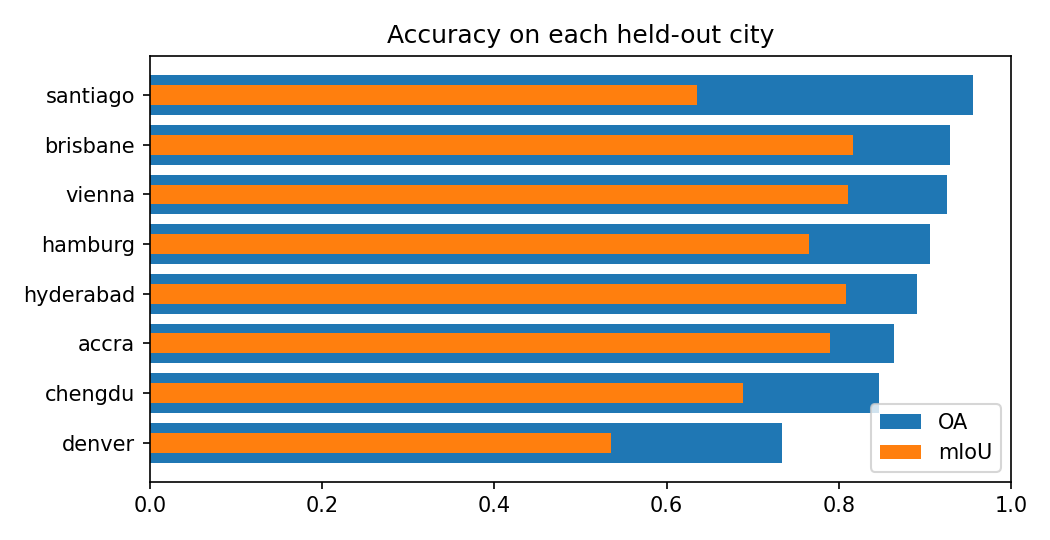

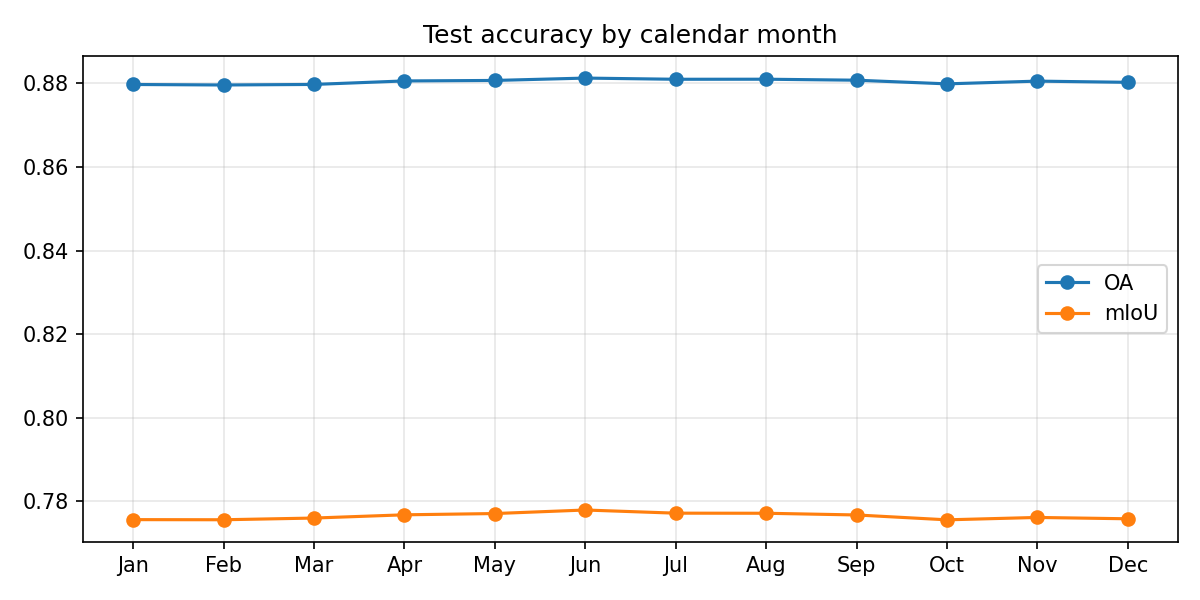

In [10]:
print("Accuracy per test city and per month:")
show_table("outputs/analysis/per_site.csv")
show_image("outputs/analysis/per_site.png", width=700)
show_image("outputs/analysis/per_month.png", width=700)

## 5. Prototype: latitude/longitude + start month -> 12 monthly maps

**Architecture.** `lulc_pipeline.run()`: (1) query Sentinel-1 RTC from the Planetary Computer for the 12 months starting at the chosen month, (2) build a **monthly median composite** (VV, VH), (3) convert to dB and average to 30 m, (4) build the 19 input channels per month, (5) run the trained U-Net (with flip averaging) for each month, (6) count the pixels of each class per month -> **percentage of the area per class**, (7) compute the **month-to-month change** and the **total change from the first to the last month in percentage points**, (8) draw the 3 x 4 map grid.
Interface: `predict.py` (command line).

The cell below runs the prototype live (internet needed). If that is not possible, the saved result of an earlier run is shown.

/home/jovyan/.local/lib/python3.11/site-packages/rasterio/warp.py:387: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dest = _reproject(


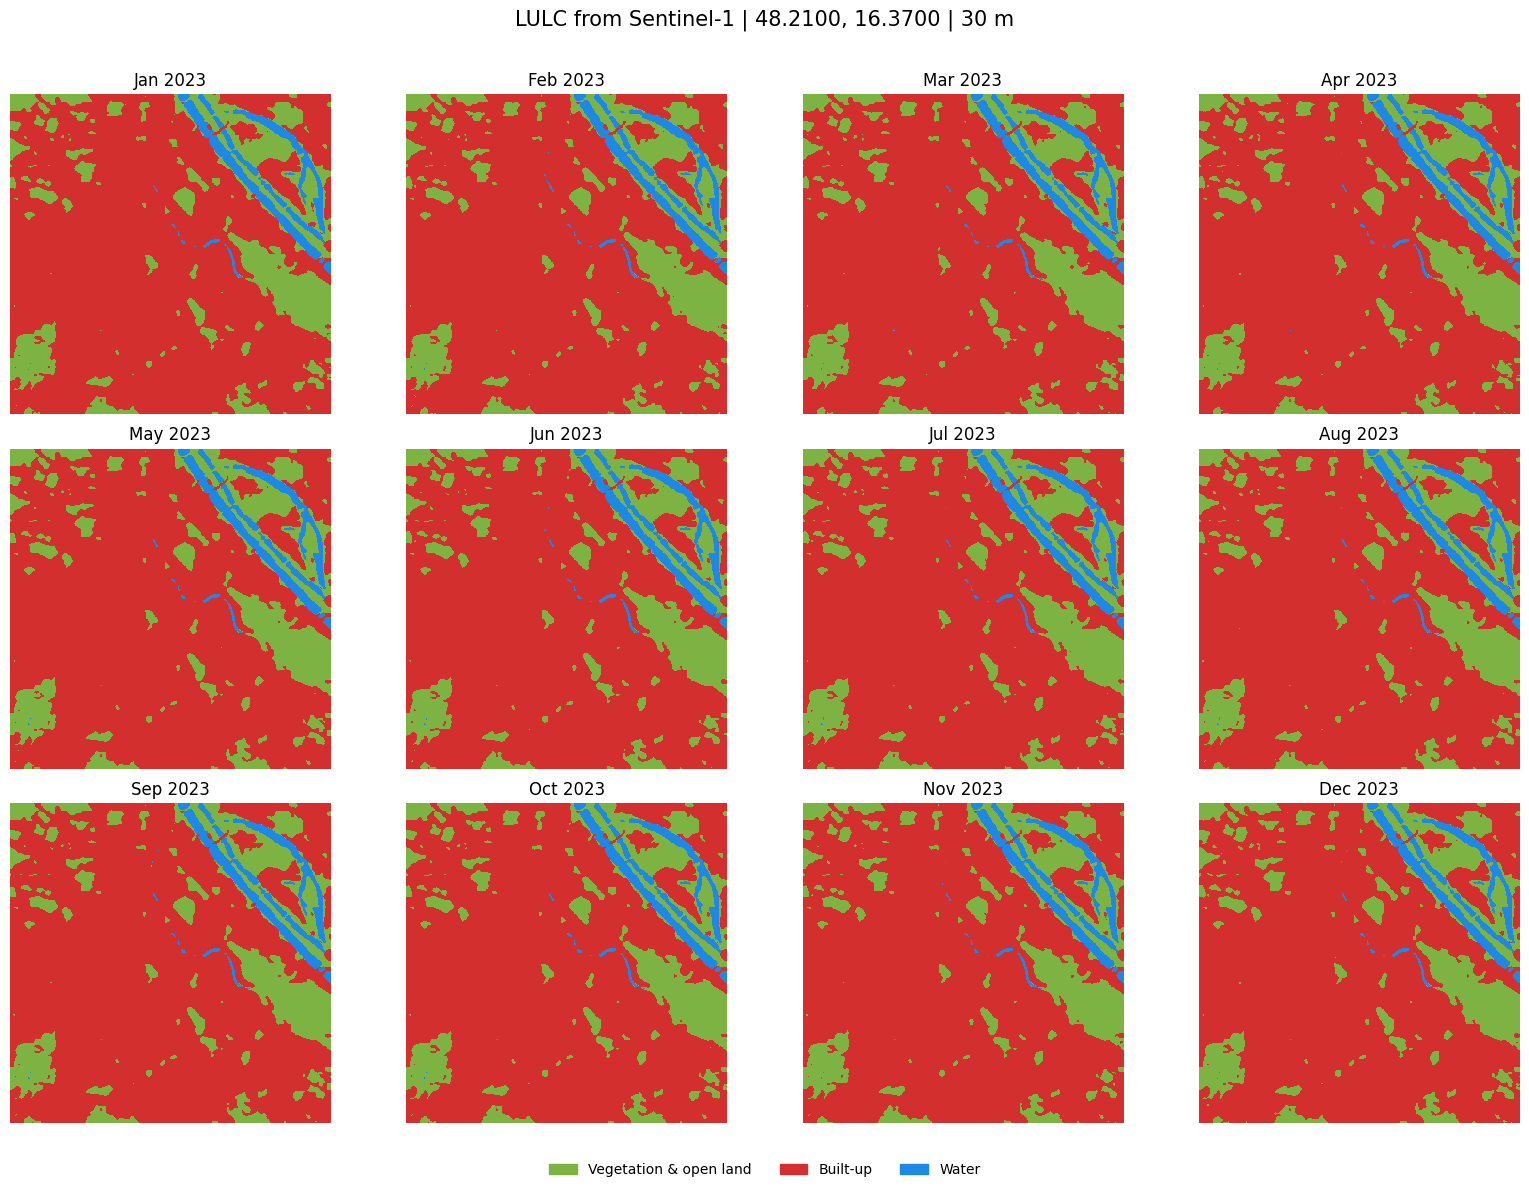


Class coverage per month (%):


,Vegetation & open land,Built-up,Water
month,,,
2023-01,18.98,76.85,4.17
2023-02,18.76,77.04,4.20
2023-03,18.93,76.88,4.18
2023-04,18.95,76.80,4.26
2023-05,18.96,76.79,4.25
2023-06,18.88,76.81,4.31
2023-07,18.84,76.93,4.23
2023-08,18.95,76.78,4.27
2023-09,18.81,76.89,4.30


Month-to-month change (percentage points):


,Vegetation & open land,Built-up,Water
2023-01 -> 2023-02,-0.22,0.19,0.03
2023-02 -> 2023-03,0.17,-0.16,-0.02
2023-03 -> 2023-04,0.02,-0.08,0.08
2023-04 -> 2023-05,0.01,-0.01,-0.01
2023-05 -> 2023-06,-0.08,0.02,0.06
2023-06 -> 2023-07,-0.04,0.12,-0.08
2023-07 -> 2023-08,0.11,-0.15,0.04
2023-08 -> 2023-09,-0.14,0.11,0.03
2023-09 -> 2023-10,0.10,-0.04,-0.05
2023-10 -> 2023-11,-0.16,0.15,0.00


Total change first -> last month (percentage points):


,Vegetation & open land,Built-up,Water
2023-01 -> 2023-12 (pp),0.38,-0.4,0.02


In [11]:
LAT, LON, START, SIZE_KM = 48.21, 16.37, "2023-01", 10.0
try:
    from lulc_pipeline import run
    r = run(LAT, LON, START, SIZE_KM, MODEL, "outputs/notebook_run", verbose=False, tta=True)
    plt.show()
    print("\nClass coverage per month (%):"); display(r["percent"])
    print("Month-to-month change (percentage points):"); display(r["month_to_month"])
    print("Total change first -> last month (percentage points):"); display(r["total_change"])
except Exception as e:
    print("Live run not possible here:", type(e).__name__, str(e)[:120])
    print("Showing the saved run for Mannheim instead.\n")
    show_image("outputs/run_maps.png", width=900)
    show_table("outputs/run_percent.csv", index_col=0)
    show_table("outputs/run_month_to_month_pp.csv", index_col=0)
    show_table("outputs/run_total_change_pp.csv", index_col=0)

### Case study with an independent map
For urban test areas the prediction is compared with the **Esri 10 m Annual Land Cover** map, which was never used for training or model selection
(`python case_study.py --name vienna --lat 48.21 --lon 16.37 --start 2023-01 --scheme 3`). Both maps are model-derived, so this is a sanity check
(agreement), not proof of the true land cover.

 case_hamburg
agreement with the independent map: OA 0.824, mIoU 0.560, F1 0.652


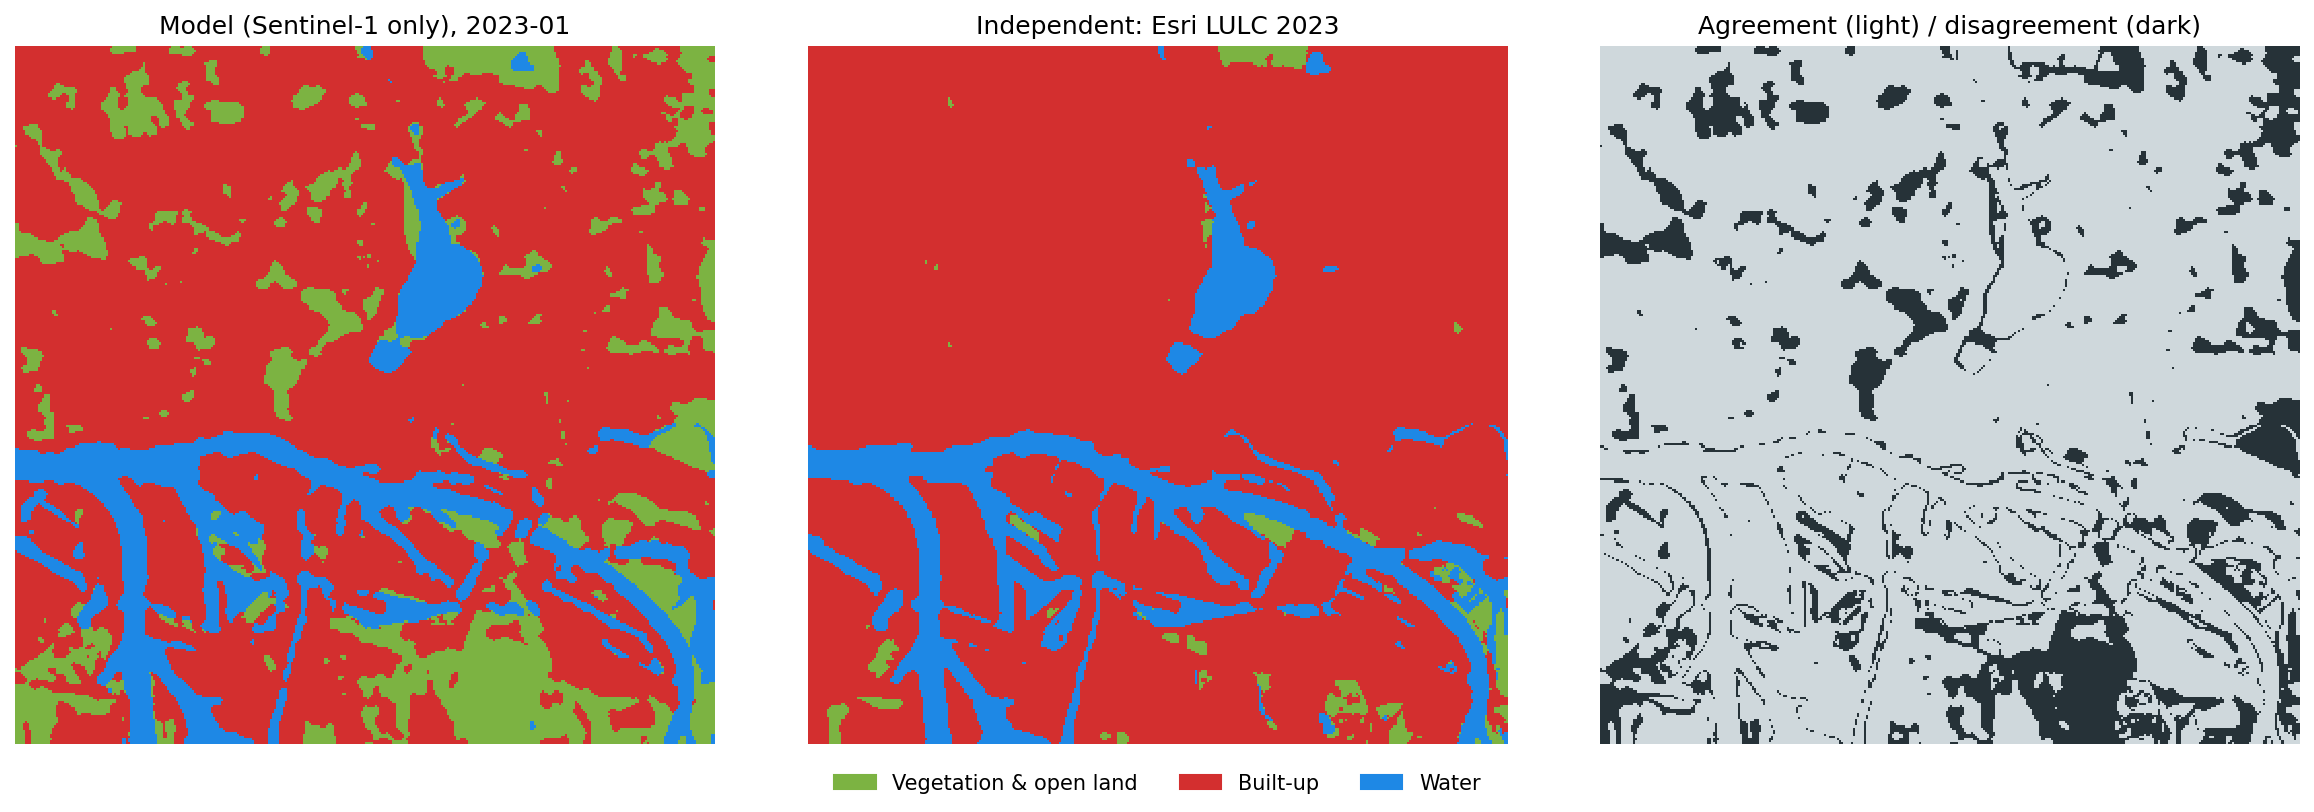

,Unnamed: 0,model_12mo_mean_%,esri_%,difference_pp
0,Vegetation & open land,16.37,2.25,14.12
1,Built-up,70.12,85.00,-14.88
2,Water,13.51,12.74,0.77


,Unnamed: 0,observed_total_change_pp,false_change_p90_pp,exceeds_noise_level
0,Vegetation & open land,-0.23,0.483,False
1,Built-up,0.26,0.485,False
2,Water,-0.02,0.076,False


 case_mannheim
agreement with the independent map: OA 0.816, mIoU 0.662, F1 0.786


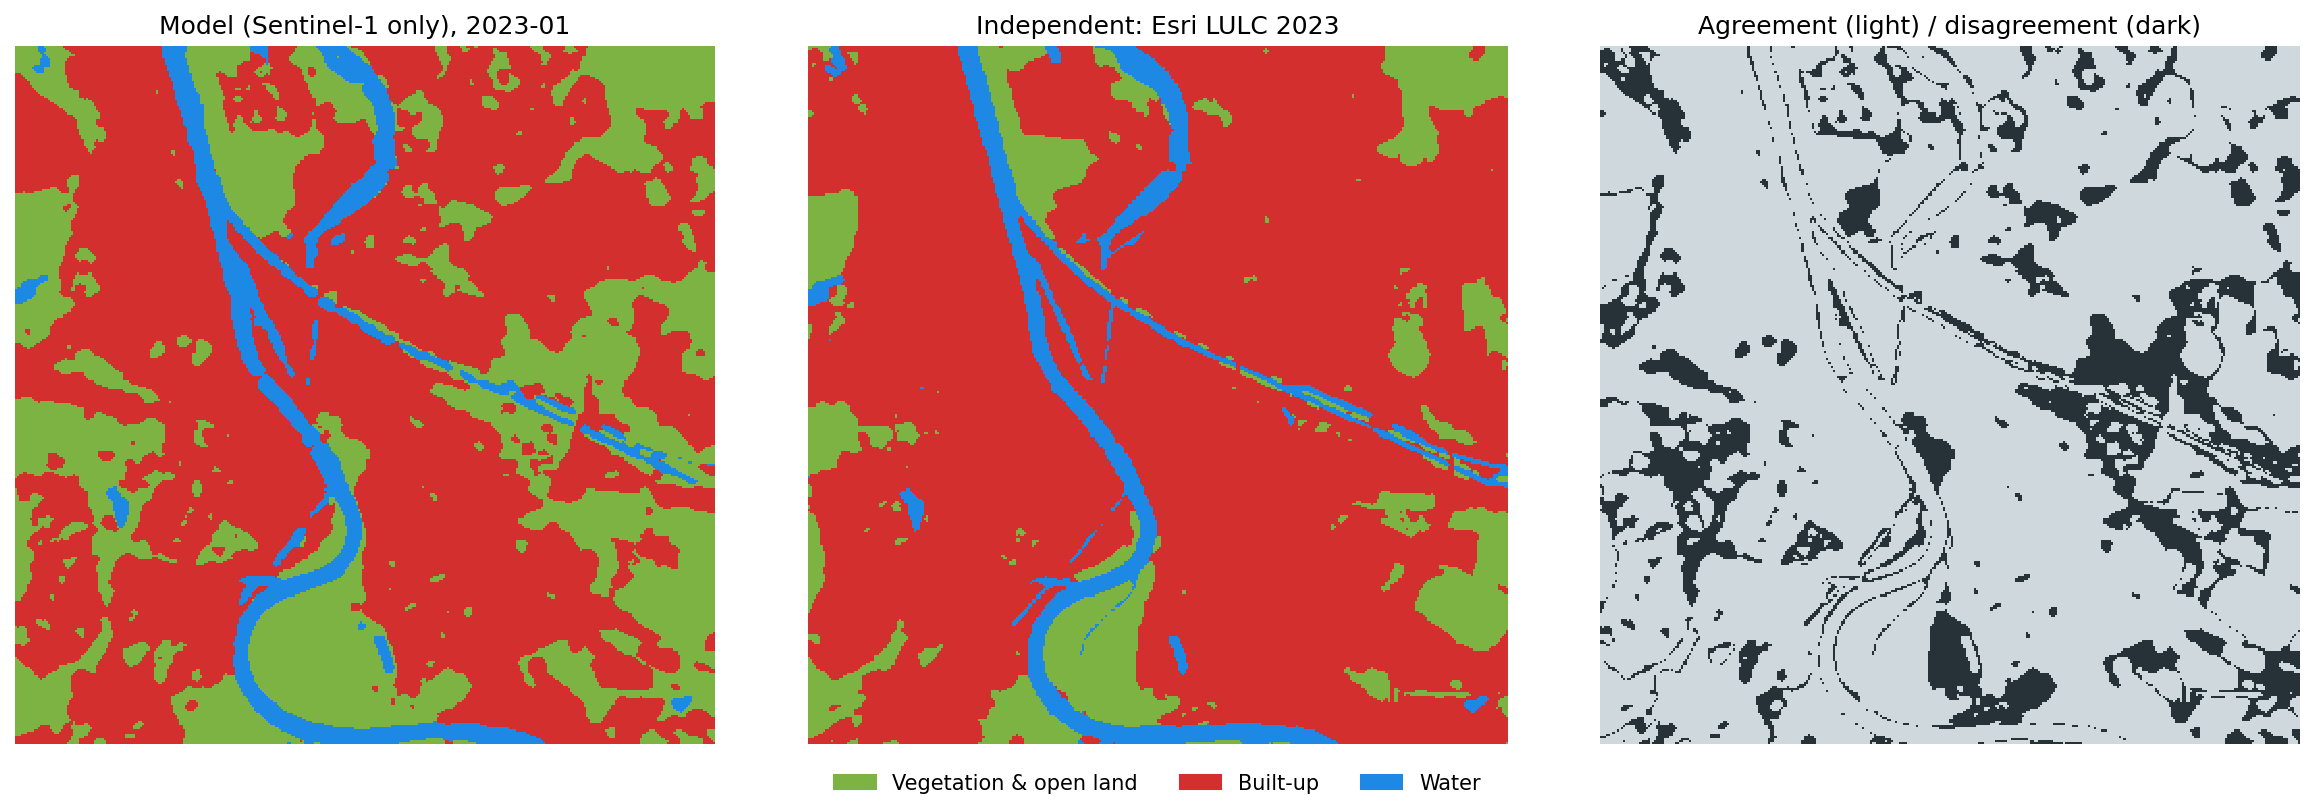

,Unnamed: 0,model_12mo_mean_%,esri_%,difference_pp
0,Vegetation & open land,30.92,14.37,16.55
1,Built-up,62.24,79.02,-16.78
2,Water,6.84,6.60,0.24


,Unnamed: 0,observed_total_change_pp,false_change_p90_pp,exceeds_noise_level
0,Vegetation & open land,-0.15,0.483,False
1,Built-up,0.12,0.485,False
2,Water,0.02,0.076,False


 case_vienna
agreement with the independent map: OA 0.849, mIoU 0.597, F1 0.710


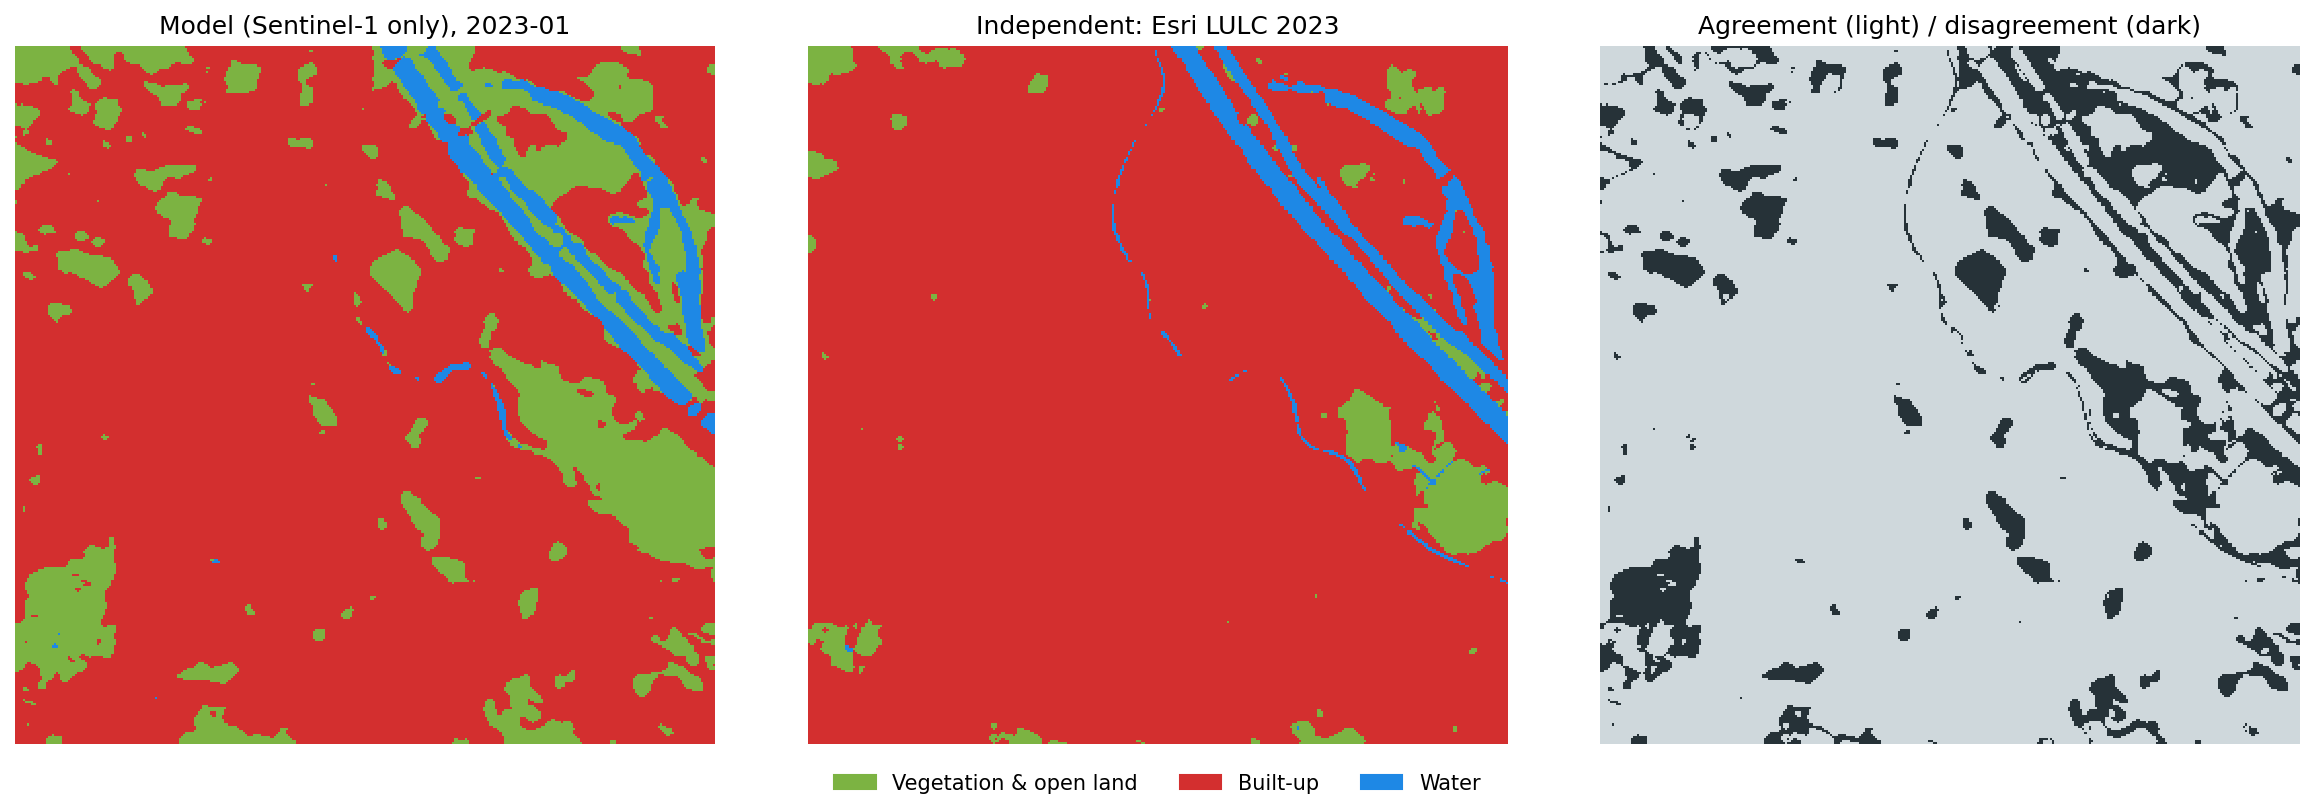

,Unnamed: 0,model_12mo_mean_%,esri_%,difference_pp
0,Vegetation & open land,18.66,4.58,14.08
1,Built-up,76.96,90.44,-13.48
2,Water,4.38,4.97,-0.59


,Unnamed: 0,observed_total_change_pp,false_change_p90_pp,exceeds_noise_level
0,Vegetation & open land,0.48,0.483,False
1,Built-up,-0.44,0.485,False
2,Water,-0.04,0.076,False


In [12]:
cases = sorted(glob.glob("outputs/case_*"))
if not cases:
    print("no case study found: run case_study.py (see above)")
for c in cases:
    name = os.path.basename(c)
    print("=" * 60, "\n", name)
    j = os.path.join(c, "independent_check.json")
    if os.path.exists(j):
        r_ = json.load(open(j)); print(f"agreement with the independent map: OA {r_['overall_acc']:.3f}, mIoU {r_['mIoU']:.3f}, F1 {r_['mF1']:.3f}")
    show_image(os.path.join(c, "independent_check.png"), width=900)
    show_table(os.path.join(c, "area_comparison.csv"))
    show_table(os.path.join(c, "total_change_vs_noise.csv"))

## 6. Critical discussion

Apparent change when the TRUE change is zero (static reference map), percentage points:


,mean_bias_pp,mean_abs_bias_pp,mean_range_over_12_months_pp,mean_abs_month_to_month_pp,mean_abs_total_change_pp,p90_abs_total_change_pp
class,,,,,,
Vegetation & open land,-3.626,6.147,0.701,0.192,0.221,0.483
Built-up,3.493,6.512,0.683,0.190,0.213,0.485
Water,0.133,0.537,0.078,0.022,0.023,0.076


{'true_change_pp': 0.0, 'mean_pixels_switching_class_per_month_pct': 0.6200940681226326, 'mean_net_area_change_per_month_pct': 0.20179979728929925, 'note': 'True change is zero (static reference map). Gross pixel switching is far larger than net area change because switches partly cancel; both are error, not change.'}


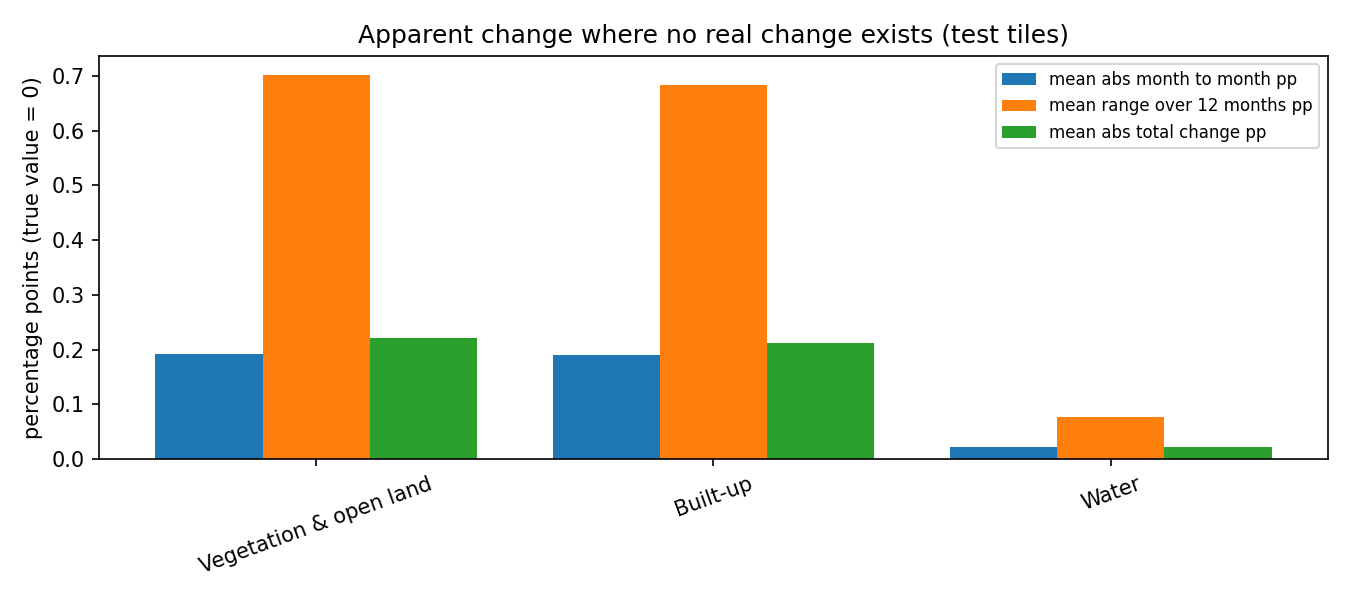

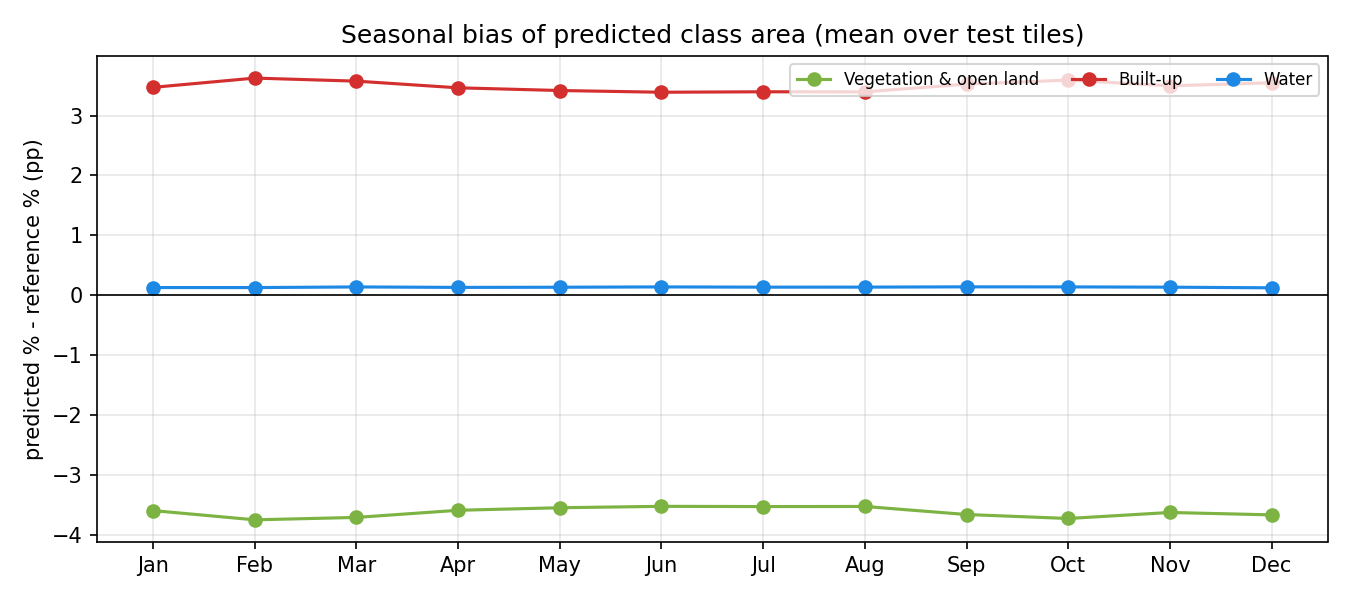

In [13]:
ci = pd.read_csv("outputs/analysis/change_inflation.csv", index_col=0)
print("Apparent change when the TRUE change is zero (static reference map), percentage points:")
display(ci.round(3))
print(json.load(open("outputs/analysis/change_inflation_summary.json")))
show_image("outputs/analysis/change_inflation.png", width=700)
show_image("outputs/analysis/seasonal_bias.png", width=700)

**Regions unlike the training data.** Accuracy ranges from 96 % (Santiago) and 93 % (Vienna, Brisbane) to **73 % in Denver**, where dry, bright ground and low buildings
look similar in SAR. Accuracy falls where the landscape differs from most training cities, and Santiago shows that a high overall accuracy can hide
weak small classes (low mIoU, because the city area is almost entirely one class).

**SAR-specific confusion.** With 6 classes the model reaches only about 70 % because trees, grass/shrub, cropland and bare soil produce similar backscatter;
the largest errors in the 6-class confusion matrix are between exactly these classes. Merging them gives 76 % (5 classes), 83 % (4 classes) and 88 % (3 classes).
This is not a better model but an easier question, so the 88 % must always be quoted together with the 6-class result. In the 3-class model, built-up
areas are overestimated (precision 0.79, recall 0.88), typically where dense vegetation or rough ground resembles urban backscatter.

**Seasonal effects.** Backscatter changes through the year (soil moisture, vegetation growth, frozen or snow-covered ground, wet snow). The 12-month statistics
give the model context, but the per-month accuracy and the monthly class shares still fluctuate slightly (see `per_month` and `seasonal_bias`).

**Errors inflating the change percentages.** The reference map is static, so the true change is zero, yet the monthly maps show apparent changes: on average
about 0.2 percentage points month to month, 0.5 points total (90th percentile), and about 0.6 % of the pixels switch class from one month to the next
(partly cancelling in the net area). The case studies show total changes of 0.1-0.2 points, **below this noise level**, so no real change is claimed.
A real change must clearly exceed about 0.5 points before it can be trusted. There is also a systematic **bias** (built-up overestimated by about 3.5 points,
vegetation underestimated by about 3.6 points on average), which does not affect month-to-month differences much but does affect absolute percentages.

**Limitations.**
* Labels are a model-derived, single-year map (WorldCover is about 77 % accurate globally), so "accuracy" is agreement with WorldCover; the Esri comparison is another model-derived map, and part of the area differences in the case study come from different class definitions.
* Training used 2021 only; other years and very different regions may reduce accuracy.
* The grouped 3-class maps are less detailed than the 6-class maps (no distinction between forest, grass and crops).
* Architecture, hyper-parameter, and feature changes gave less than one point; the remaining limit is the data and the label quality, and more training cities helped most.

## 7. Conclusion
A U-Net trained only on low-resolution Sentinel-1 data produces monthly land-cover maps with **88 % accuracy on unseen cities for 3 classes** (about 70 % for the 6 original classes).
The prototype turns a latitude/longitude and a start month into 12 monthly maps, class percentages and change in percentage points. The false-change analysis shows
that changes below about 0.5 percentage points cannot be distinguished from classification noise.